In [1]:
import joblib
dane = joblib.load("clean_data.pkl")
dane.head()

c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\pandas\io\formats\format.py:1466: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,id,name,neighbourhood_group,room_type,price,rating,bedrooms,beds,baths
0,1312228,Rental unit in Brooklyn · ★5.0 · 1 bedroom,Brooklyn,Private room,55.0,5.000000,1,1,NaN
1,45277537,Rental unit in New York · ★4.67 · 2 bedrooms ·...,Manhattan,Entire home/apt,144.0,4.671875,2,1,1.0
2,971353993633883038,Rental unit in New York · ★4.17 · 1 bedroom · ...,Manhattan,Entire home/apt,187.0,4.171875,1,2,1.0
3,3857863,Rental unit in New York · ★4.64 · 1 bedroom · ...,Manhattan,Private room,120.0,4.640625,1,1,1.0
4,40896611,Condo in New York · ★4.91 · Studio · 1 bed · 1...,Manhattan,Entire home/apt,85.0,4.910156,0,1,1.0


In [2]:
dane['price'].describe()

count     20758.000000
mean        187.776611
std        1022.797180
min          10.000000
25%          80.000000
50%         125.000000
75%         199.000000
max      100000.000000
Name: price, dtype: float64

In [3]:
dane.groupby('room_type')['price'].mean()

room_type
Entire home/apt    223.160278
Hotel room         415.053558
Private room       139.517380
Shared room        156.286682
Name: price, dtype: float32

In [4]:
dane.groupby('bedrooms')['price'].mean() # 0 to studio

bedrooms
0      159.070526
1      150.493408
2      242.096619
3      317.291962
4      518.550720
5      435.482147
6      883.310364
7      494.000000
8     1281.800049
9      706.666687
14    2136.000000
15    1815.000000
Name: price, dtype: float32

In [5]:
dane.groupby('neighbourhood_group')['price'].mean()  #najdroższe mieszkania są na manhatanie

neighbourhood_group
Bronx            118.407799
Brooklyn         187.033936
Manhattan        227.854187
Queens           126.489235
Staten Island    118.780067
Name: price, dtype: float32

In [6]:
dane['bedrooms'].value_counts()

bedrooms
1     13439
2      3602
0      1815
3      1394
4       345
5       112
6        29
7         9
9         6
8         5
15        1
14        1
Name: count, dtype: int64

In [7]:
city = dane.groupby(['neighbourhood_group', 'room_type'])['price'].mean()
city

neighbourhood_group  room_type      
Bronx                Entire home/apt    149.043594
                     Private room        97.301468
                     Shared room         87.333336
Brooklyn             Entire home/apt    210.741348
                     Hotel room         162.750000
                     Private room       161.658783
                     Shared room        105.959015
Manhattan            Entire home/apt    253.747345
                     Hotel room         442.326721
                     Private room       163.450623
                     Shared room        319.558441
Queens               Entire home/apt    179.928757
                     Hotel room         165.714279
                     Private room        87.384140
                     Shared room         84.053337
Staten Island        Entire home/apt    139.852570
                     Private room        92.389313
                     Shared room        161.250000
Name: price, dtype: float32

In [8]:
city = city.unstack()
city

room_type,Entire home/apt,Hotel room,Private room,Shared room
neighbourhood_group,,,,
Bronx,149.043594,NaN,97.301468,87.333336
Brooklyn,210.741348,162.750000,161.658783,105.959015
Manhattan,253.747345,442.326721,163.450623,319.558441
Queens,179.928757,165.714279,87.384140,84.053337
Staten Island,139.852570,NaN,92.389313,161.250000


<Axes: xlabel='neighbourhood_group'>

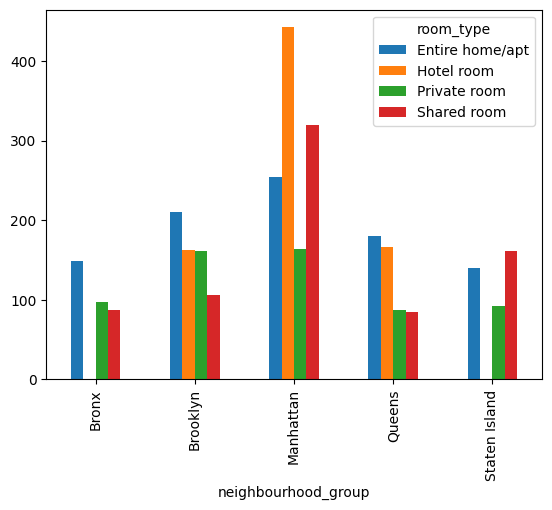

In [9]:
city.plot(kind = 'bar')

<Axes: >

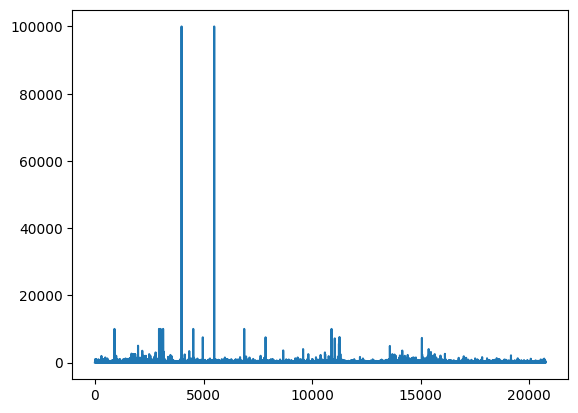

In [10]:
cena = dane['price']
cena.plot()

In [11]:
cena.describe()

count     20758.000000
mean        187.776611
std        1022.797180
min          10.000000
25%          80.000000
50%         125.000000
75%         199.000000
max      100000.000000
Name: price, dtype: float64

In [12]:
dane.nlargest(10, "price")

c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\pandas\io\formats\format.py:1466: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,id,name,neighbourhood_group,room_type,price,rating,bedrooms,beds,baths
3990,17160286,Rental unit in Brooklyn · ★4.48 · 1 bedroom · ...,Brooklyn,Private room,100000.0,4.480469,1,1,1.0
5492,605115521796576121,Rental unit in Brooklyn · ★4.33 · 1 bedroom · ...,Brooklyn,Private room,100000.0,4.328125,1,1,1.0
901,38993679,Boutique hotel in New York · 1 bedroom · 1 bed...,Manhattan,Private room,10000.0,NaN,1,1,1.0
2952,13925864,Rental unit in Queens · ★4.14 · 2 bedrooms · 2...,Queens,Entire home/apt,10000.0,4.140625,2,2,1.0
3026,31219800,Loft in New York · ★4.50 · 4 bedrooms · 5 beds...,Manhattan,Shared room,10000.0,4.500000,4,5,2.0
3140,38993493,Boutique hotel in New York · ★3.40 · 1 bedroom...,Manhattan,Private room,10000.0,3.400391,1,2,1.0
4528,38993556,Boutique hotel in New York · ★3.33 · 1 bedroom...,Manhattan,Private room,10000.0,3.330078,1,1,1.0
6874,52862058,Rental unit in New York · Studio · 1 bed · 1 bath,Manhattan,Entire home/apt,10000.0,NaN,0,1,1.0
10894,49920227,Home in Bronx · ★4.30 · 1 bedroom · 1 bed · 1 ...,Bronx,Private room,9994.0,4.300781,1,1,1.0
11261,34490359,Hotel in NEW YORK · ★5.0 · 1 bedroom · 1 bed ·...,Manhattan,Hotel room,7590.0,5.000000,1,1,1.0


In [13]:
dane[dane['price'] > 5000]

c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\pandas\io\formats\format.py:1466: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,id,name,neighbourhood_group,room_type,price,rating,bedrooms,beds,baths
901,38993679,Boutique hotel in New York · 1 bedroom · 1 bed...,Manhattan,Private room,10000.0,NaN,1,1,1.0
2952,13925864,Rental unit in Queens · ★4.14 · 2 bedrooms · 2...,Queens,Entire home/apt,10000.0,4.140625,2,2,1.0
3026,31219800,Loft in New York · ★4.50 · 4 bedrooms · 5 beds...,Manhattan,Shared room,10000.0,4.500000,4,5,2.0
3140,38993493,Boutique hotel in New York · ★3.40 · 1 bedroom...,Manhattan,Private room,10000.0,3.400391,1,2,1.0
3990,17160286,Rental unit in Brooklyn · ★4.48 · 1 bedroom · ...,Brooklyn,Private room,100000.0,4.480469,1,1,1.0
4528,38993556,Boutique hotel in New York · ★3.33 · 1 bedroom...,Manhattan,Private room,10000.0,3.330078,1,1,1.0
4967,8069030,Rental unit in Brooklyn · ★4.78 · 4 bedrooms ·...,Brooklyn,Entire home/apt,7498.0,4.781250,4,5,2.0
5492,605115521796576121,Rental unit in Brooklyn · ★4.33 · 1 bedroom · ...,Brooklyn,Private room,100000.0,4.328125,1,1,1.0
6874,52862058,Rental unit in New York · Studio · 1 bed · 1 bath,Manhattan,Entire home/apt,10000.0,NaN,0,1,1.0
7857,15345019,"Place to stay in Greenpoint, Brooklyn · ★4.76 ...",Brooklyn,Private room,7500.0,4.761719,2,1,1.0


In [14]:
iqr = 199.000000 - 80.000000
high = 199.000000 + 1.5 * iqr

In [15]:
print(iqr)
print(high)

119.0
377.5


In [16]:
dane[dane["price"] > 377.5]

c:\Users\wikto\AppData\Local\Programs\Python\Python313\Lib\site-packages\pandas\io\formats\format.py:1466: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,id,name,neighbourhood_group,room_type,price,rating,bedrooms,beds,baths
15,29923599,Serviced apartment in New York City · Studio ·...,Manhattan,Hotel room,1000.0,NaN,0,2,1.0
17,34718504,Condo in New York · 2 bedrooms · 2 beds · 2 baths,Manhattan,Entire home/apt,425.0,NaN,2,2,2.0
47,1027808,Loft in New York · ★4.87 · 2 bedrooms · 1 bed ...,Manhattan,Entire home/apt,450.0,4.871094,2,1,2.0
49,1146653,Condo in New York · ★4.90 · 2 bedrooms · 1 bed...,Manhattan,Entire home/apt,1000.0,4.898438,2,1,1.0
64,807172063275763015,Home in Queens · ★4.50 · 6 bedrooms · 8 beds ·...,Queens,Entire home/apt,900.0,4.500000,6,8,4.0
...,...,...,...,...,...,...,...,...,...
20664,40239461,Townhouse in Brooklyn · ★4.50 · 2 bedrooms · 2...,Brooklyn,Entire home/apt,400.0,4.500000,2,2,2.0
20682,31001555,Boutique hotel in New York · ★5.0 · 1 bedroom ...,Manhattan,Private room,1150.0,5.000000,1,1,1.0
20698,27200105,Rental unit in Brooklyn · ★4.84 · 2 bedrooms ·...,Brooklyn,Entire home/apt,395.0,4.839844,2,2,1.5
20718,45505393,Rental unit in New York · ★5.0 · 2 bedrooms · ...,Manhattan,Entire home/apt,700.0,5.000000,2,2,2.0


In [17]:
dane[dane["price"] > 1000].shape[0]

168

In [18]:
procent_zbioru = 168/20758*100
procent_zbioru

0.8093265247133635

In [19]:
do_tys = dane['price'][dane['price']<= 1000]
do_tys.describe()

count    20590.000000
mean       161.258179
std        131.956451
min         10.000000
25%         80.000000
50%        125.000000
75%        199.000000
max       1000.000000
Name: price, dtype: float64

<Axes: >

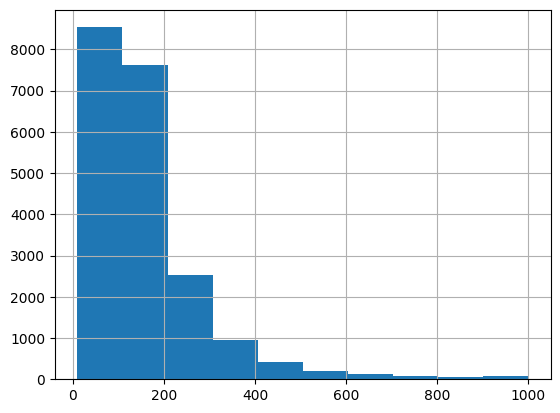

In [20]:
do_tys.hist()

In [21]:
dane_do_1000 = dane[dane["price"] <= 1000]

<Axes: title={'center': 'price'}, xlabel='room_type'>

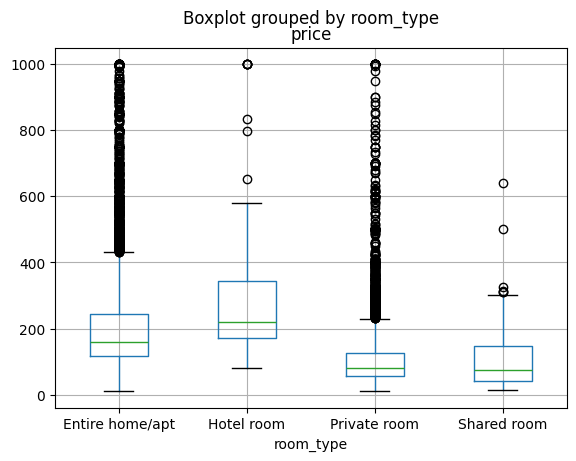

In [22]:
dane_do_1000.boxplot(column='price', by = 'room_type')

In [23]:
dane["rating"] = dane["rating"].astype("float32")

In [24]:
dane_do_1000 = dane[dane["price"] <= 1000]

<Axes: xlabel='rating', ylabel='price'>

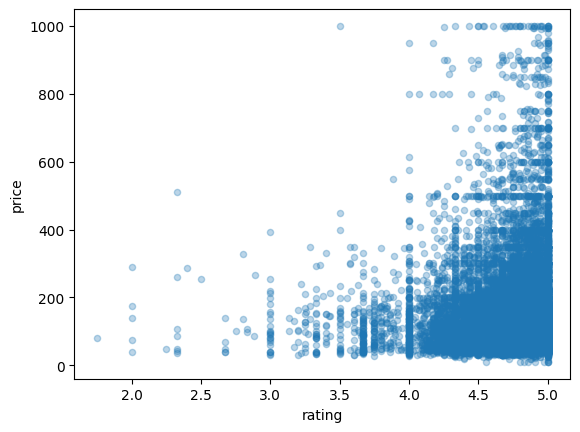

In [25]:
dane_do_1000.plot.scatter(x="rating",y="price",alpha=0.3)

In [26]:
dane_do_1000[['rating', 'price']].corr() #słaba korelacja ratingu do ceny 

,rating,price
rating,1.000000,0.097303
price,0.097303,1.000000


In [27]:
dane_do_1000[['price', 'bedrooms', 'beds', 'baths']].corr() #Liczba łóżek i sypialni wykazuje umiarkowaną dodatnią zależność z ceną. Liczba łazienek również jest dodatnio związana z ceną, ale słabiej. Spośród tych cech najsilniej z ceną koreluje liczba łóżek.

,price,bedrooms,beds,baths
price,1.000000,0.402973,0.421339,0.312141
bedrooms,0.402973,1.000000,0.685517,0.439672
beds,0.421339,0.685517,1.000000,0.358096
baths,0.312141,0.439672,0.358096,1.000000
